# **Task 3 — Notebook: Blackbody Radiation & Wien's Law**

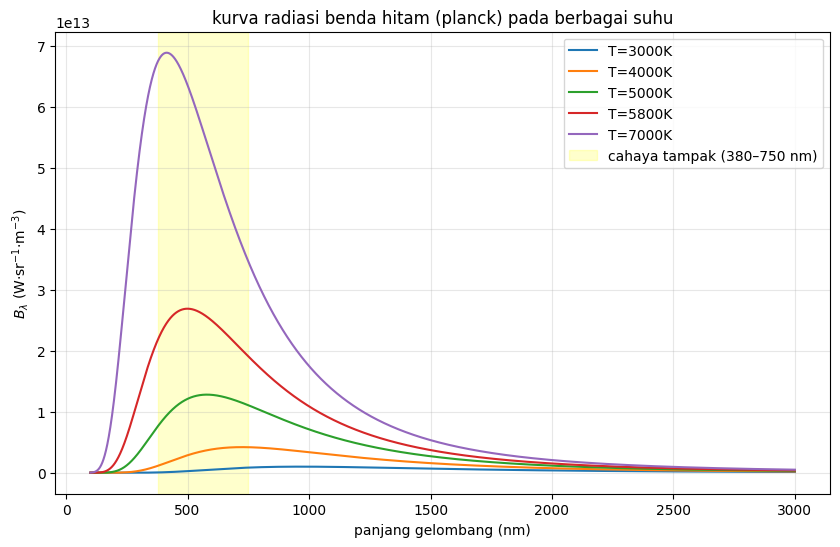

T=3000K maka λ_max=965.9 nm
T=4000K maka λ_max=724.4 nm
T=5000K maka λ_max=579.5 nm
T=5800K maka λ_max=499.6 nm
T=7000K maka λ_max=414.0 nm
  T(K)  b hitung (m·K)  error(%)
  3000      2.8978e-03    0.0083
  4000      2.8977e-03    0.0091
  5000      2.8977e-03    0.0088
  5800      2.8978e-03    0.0062
  7000      2.8977e-03    0.0104

b rata-rata=2.8978e-03m·K
b teoritis=2.8980e-03m·K
error rata-rata=0.0086%


In [7]:
import numpy as np
import matplotlib.pyplot as plt

h=6.62607015e-34
c=2.99792458e8
kB=1.380649e-23

def planck(lam,T):
    return (2*h*c**2/lam**5)/(np.exp(h*c/(lam*kB*T))-1)

lam=np.linspace(100e-9,3000e-9,100000)
temps=[3000,4000,5000,5800,7000]

plt.figure(figsize=(10,6))
for T in temps:
    plt.plot(lam*1e9,planck(lam,T),label=f"T={T}K")

plt.axvspan(380,750,color="yellow",alpha=0.2,label="cahaya tampak (380–750 nm)")
plt.xlabel("panjang gelombang (nm)")
plt.ylabel(r"$B_\lambda$ (W·sr$^{-1}$·m$^{-3}$)")
plt.title("kurva radiasi benda hitam (planck) pada berbagai suhu")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

lam_max={}
for T in temps:
    B=planck(lam,T)
    lam_max[T]=lam[np.argmax(B)]
    print(f"T={T}K maka λ_max={lam_max[T]*1e9:.1f} nm")

b_teori=2.898e-3 # m·K

print(f"{'T(K)':>6}{'b hitung (m·K)':>16}{'error(%)':>10}")
b_list=[]
for T in temps:
    b=lam_max[T]*T
    b_list.append(b)
    err=abs(b-b_teori)/b_teori*100
    print(f"{T:6d}{b:16.4e}{err:10.4f}")

b_rata=np.mean(b_list)
print(f"\nb rata-rata={b_rata:.4e}m·K")
print(f"b teoritis={b_teori:.4e}m·K")
print(f"error rata-rata={abs(b_rata-b_teori)/b_teori*100:.4f}%")

Untuk T≈5800 K, λ_max≈500 nm. Puncak ini berada di dalam rentang cahaya tampak (380–750 nm), di daerah biru-hijau menuju hijau, sehingga sebagian besar energi matahari dipancarkan sebagai cahaya tampak. Puncaknya dekat dengan daerah hijau-kuning, tempat mata manusia paling sensitif. Hal ini masuk akal karean mata peka pada bagian spektrum yang paling banyak tersedia dari Matahari.

# **Task 4 — Notebook: Simulasi Pengukuran Superposition**

Σ|c_i|²= 0.9999999999999999
ternormalisasi: True
P(keadaan 1)=0.2500
P(keadaan 2)=0.5000
P(keadaan 3)=0.2500
N=   10 maka cacah=[2 3 5], frekuensi relatif=[0.2 0.3 0.5]
N=  100 maka cacah=[25 53 22], frekuensi relatif=[0.25 0.53 0.22]
N= 1000 maka cacah=[258 485 257], frekuensi relatif=[0.258 0.485 0.257]
N=10000 maka cacah=[2520 5025 2455], frekuensi relatif=[0.252  0.5025 0.2455]


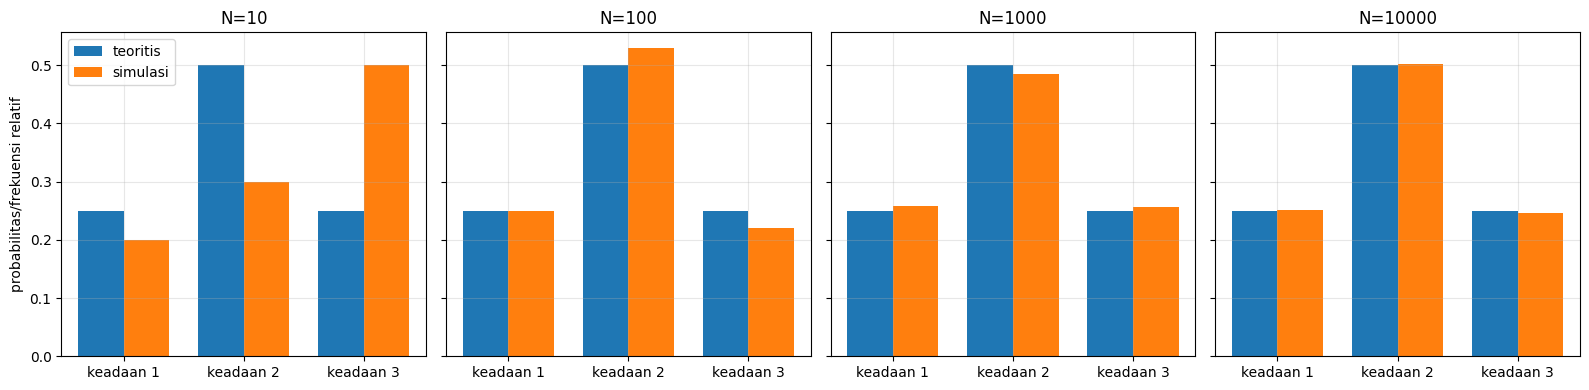

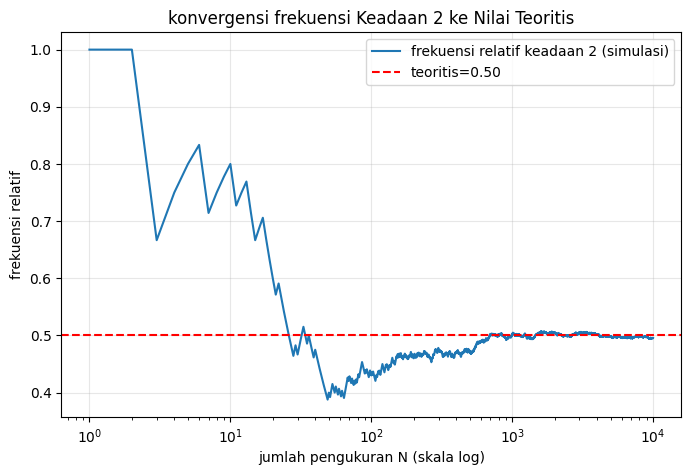

probabilitas lama: [0.25 0.5  0.25]
probabilitas baru: [0.25 0.5  0.25]
ternormalisasi: True


In [11]:
import numpy as np
import matplotlib.pyplot as plt

c=np.array([1/2,1/np.sqrt(2),1j/2])

norm=np.sum(np.abs(c)**2)
print("Σ|c_i|²=",norm)
print("ternormalisasi:",np.isclose(norm,1.0))

probs=np.abs(c)**2
for i,p in enumerate(probs,start=1):
    print(f"P(keadaan {i})={p:.4f}")

rng=np.random.default_rng(seed=42)
Ns=[10,100,1000,10000]
freqs={}

for N in Ns:
    outcomes=rng.choice([0,1,2],size=N,p=probs)
    counts=np.bincount(outcomes,minlength=3)
    freqs[N]=counts/N
    print(f"N={N:5d} maka cacah={counts}, frekuensi relatif={np.round(freqs[N],4)}")

fig,axes=plt.subplots(1,4,figsize=(16,4),sharey=True)
x=np.arange(3)
w=0.38

for ax,N in zip(axes,Ns):
    ax.bar(x-w/2,probs,w,label="teoritis")
    ax.bar(x+w/2,freqs[N],w,label="simulasi")
    ax.set_xticks(x)
    ax.set_xticklabels(["keadaan 1","keadaan 2","keadaan 3"])
    ax.set_title(f"N={N}")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("probabilitas/frekuensi relatif")
axes[0].legend()
plt.tight_layout()
plt.show()

N_max=10000
outcomes=rng.choice([0,1,2],size=N_max,p=probs)
n=np.arange(1,N_max+1)
freq_2=np.cumsum(outcomes==1)/n

plt.figure(figsize=(8,5))
plt.semilogx(n,freq_2,label="frekuensi relatif keadaan 2 (simulasi)")
plt.axhline(probs[1],color="red",linestyle="--",label=f"teoritis={probs[1]:.2f}")
plt.xlabel("jumlah pengukuran N (skala log)")
plt.ylabel("frekuensi relatif")
plt.title("konvergensi frekuensi Keadaan 2 ke Nilai Teoritis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

c_baru=np.array([1/2,1/np.sqrt(2),-1/2])
probs_baru=np.abs(c_baru)**2

print("probabilitas lama:",np.round(probs,4))
print("probabilitas baru:",np.round(probs_baru,4))
print("ternormalisasi:",np.isclose(np.sum(probs_baru),1.0))

## Normalisasi

Keadaan ternormalisasi jika $\sum_i|c_i|^2=1$.

$$
|c_1|^2=\left(\frac{1}{2}\right)^2=\frac{1}{4}
$$

$$
|c_2|^2=\left(\frac{1}{\sqrt{2}}\right)^2=\frac{1}{2}
$$

$$
|c_3|^2=\left|\frac{i}{2}\right|^2=\left(\frac{i}{2}\right)\left(\frac{-i}{2}\right)=\frac{1}{4}
$$

Jumlahnya:

$$
|c_1|^2+|c_2|^2+|c_3|^2=\frac{1}{4}+\frac{1}{2}+\frac{1}{4}=1
$$

Jadi keadaan tersebut ternormalisasi.

## Pengaruh Fase

Jika $c_3=-\frac{1}{2}$, maka:

$$
|c_3|^2=\left(-\frac{1}{2}\right)^2=\frac{1}{4}
$$

Nilainya tetap sama, sehingga probabilitas tidak berubah. Probabilitas hanya bergantung pada kuadrat besar koefisien, $|c_i|^2$, bukan pada tanda atau fasenya. Jadi, untuk pengukuran seperti ini, fase koefisien tidak memengaruhi probabilitas hasil.